# Model 03: Catalog Classification
### College Data Mining & DWDM Laboratory Submission
**Algorithm:** Decision Tree Classifier  
**Problem Type:** Multiclass Classification  
**Key Concepts Demonstrated:**
- Syllabus-aligned algorithm implementation
- Data preprocessing & descriptive statistics
- Model training, hyperparameter tuning & evaluation
- Joblib model serialization and sample inference


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

# Ensure parent directory is in path
sys.path.append(os.path.abspath(".."))
from preprocessing.preprocess import load_dataset, clean_and_impute

# Load and clean dataset
df = load_dataset()
df_clean = clean_and_impute(df)
print(f"Dataset ready: {df_clean.shape[0]} rows, {df_clean.shape[1]} columns")
df_clean.head(3)


Dataset ready: 1000 rows, 30 columns


,date,day_of_week,is_weekend,product_name,category,price,discount,previous_day_sales,sales_7_day_average,sales_30_day_average,...,sales_90_day,turnover_rate,days_since_last_sale,category_label,inventory_status,business_activity,total_expense,expense_3_month_average,average_order_value,profit
0,2024-01-01,Monday,0,Laundry Detergent 1kg,Household,210.0,10.43,3599.34,3599.34,3599.34,...,205357.08,3.62,12,MEDIUM_DEMAND,RESTOCK,14.87,3044.67,3044.67,97.28,-275.43
1,2024-01-02,Tuesday,0,Basmati Rice 5kg,Grocery,450.0,2.96,3599.34,3656.81,3656.81,...,316258.19,3.77,1,MEDIUM_DEMAND,RESTOCK,15.39,3100.65,3072.66,95.24,-358.75
2,2024-01-03,Wednesday,0,Organic Honey 500g,Grocery,280.0,6.88,3714.28,3750.13,3750.13,...,159407.77,5.20,0,MEDIUM_DEMAND,RESTOCK,12.33,3445.75,3197.02,115.79,-448.90


In [2]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

feature_cols = ["quantity_sold", "sales_30_day", "current_stock", "turnover_rate", "days_since_last_sale", "sales_90_day"]
X = df_clean[feature_cols].values
y = df_clean["category_label"].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Tune max_depth and min_samples_split
param_grid = {'max_depth': [3, 4, 5], 'min_samples_split': [2, 5, 10]}
grid = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid, cv=5, scoring='f1_macro')
grid.fit(X_train, y_train)

best_tree = grid.best_estimator_
y_pred = best_tree.predict(X_test)

print(f"Best Parameters: {grid.best_params_}")
print(f"Accuracy:        {accuracy_score(y_test, y_pred)*100:.2f}%")
print(f"Macro F1-Score:  {f1_score(y_test, y_pred, average='macro'):.4f}")


Best Parameters: {'max_depth': 4, 'min_samples_split': 2}
Accuracy:        98.50%
Macro F1-Score:  0.9861


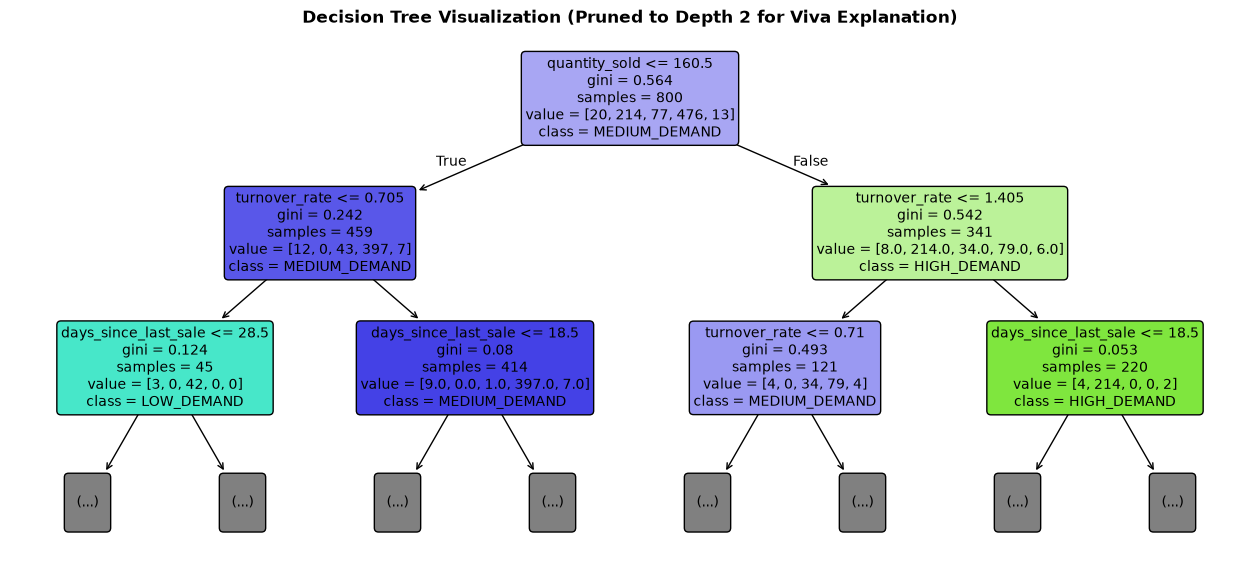

In [3]:
# Plot Decision Tree
plt.figure(figsize=(16, 7))
plot_tree(best_tree, feature_names=feature_cols, class_names=sorted(list(set(y))), filled=True, rounded=True, max_depth=2, fontsize=10)
plt.title("Decision Tree Visualization (Pruned to Depth 2 for Viva Explanation)", fontsize=12, fontweight='bold')
plt.show()


In [4]:
# Joblib Save & Test
joblib.dump(best_tree, "../models/catalog_model.joblib")
del best_tree
loaded_tree = joblib.load("../models/catalog_model.joblib")

sample = np.array([[220, 15000.0, 30, 2.5, 0, 46500.0]])
print(f"Classified Catalog Tier: {loaded_tree.predict(sample)[0]}")


Classified Catalog Tier: HIGH_DEMAND
